# 🏡 Prediksi Harga Tanah Solo Raya 2020 (100% From Scratch)

Notebook ini memprediksi harga tanah per meter persegi (`harga_tanah_rata_rata_rp_m2`) pada 127 kecamatan di Solo Raya menggunakan data `harga_tanah_2020.csv` dan `variabel_pendukung_2020.csv`.

### Aturan Implementasi:
* Seluruh algoritma ML, matriks, dan metrik ditulis **100% *from scratch*** (`numpy`, `pandas`, `math`) tanpa *scikit-learn*, *statsmodels*, atau *mgwr*.
* Menggunakan skema validasi ketat **Leave-One-Kabupaten/Kota-Out (7 lipatan luar)** untuk mencegah *spatial data leakage*.
* Standardisasi fitur dan transformasi logaritma natural target $\ln(Y)$ dihitung per lipatan latih.

In [60]:
import math
import os
import numpy as np
import pandas as pd

# ==============================================================================
# 1. GEOSPASIAL & PREPROCESSING FROM SCRATCH
# ==============================================================================

def haversine_km(lat1, lon1, lat2, lon2, radius_km=6371.0088):
    """
    Menghitung matriks jarak Haversine (km) antara titik (lat1, lon1) dan (lat2, lon2).
    """
    lat1_r = np.radians(np.asarray(lat1, dtype=float))[:, None]
    lon1_r = np.radians(np.asarray(lon1, dtype=float))[:, None]
    lat2_r = np.radians(np.asarray(lat2, dtype=float))[None, :]
    lon2_r = np.radians(np.asarray(lon2, dtype=float))[None, :]

    dlat = lat2_r - lat1_r
    dlon = lon2_r - lon1_r

    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1_r) * np.cos(lat2_r) * np.sin(dlon / 2.0) ** 2
    c = 2.0 * np.arcsin(np.minimum(1.0, np.sqrt(a)))
    return radius_km * c

def fit_standardizer(X):
    """Menghitung mean dan std per kolom (hanya dari data latih)."""
    X = np.asarray(X, dtype=float)
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0, ddof=0)
    std = np.where(std == 0, 1.0, std)
    return mean, std

def apply_standardizer(X, mean, std):
    """Menerapkan transformasi standardisasi ke matriks fitur."""
    return (np.asarray(X, dtype=float) - mean) / std

# ==============================================================================
# 2. METRIK EVALUASI & KORELASI FROM SCRATCH
# ==============================================================================

def mae_scratch(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return float(np.mean(np.abs(y_true - y_pred)))

def rmse_scratch(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

def mape_scratch(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    if not np.any(mask):
        return 0.0
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100.0)

def r2_scratch(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    ss_res = float(np.sum((y_true - y_pred) ** 2))
    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    return 1.0 - (ss_res / ss_tot) if ss_tot != 0 else 0.0

def pearson_corr_scratch(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_c = x - np.mean(x)
    y_c = y - np.mean(y)
    denom = np.sqrt(np.sum(x_c ** 2) * np.sum(y_c ** 2))
    return float(np.sum(x_c * y_c) / denom) if denom != 0 else 0.0

def rank_data_scratch(a):
    """Perankingan data dengan average rank untuk nilai kembar (ties)."""
    a = np.asarray(a, dtype=float)
    temp = np.argsort(a)
    sorted_a = a[temp]
    vals, inv, counts = np.unique(sorted_a, return_inverse=True, return_counts=True)

    tie_ranks = np.zeros(len(vals), dtype=float)
    idx = 0
    for i, count in enumerate(counts):
        tie_ranks[i] = idx + 1 + (count - 1) / 2.0
        idx += count

    ranks = tie_ranks[inv]
    rev_temp = np.empty_like(temp)
    rev_temp[temp] = np.arange(len(a))
    return ranks[rev_temp]

def spearman_corr_scratch(x, y):
    """Korelasi rank Spearman from scratch."""
    rx = rank_data_scratch(x)
    ry = rank_data_scratch(y)
    return pearson_corr_scratch(rx, ry)

print("✅ Modul Utilitas & Metrik From Scratch siap digunakan.")

✅ Modul Utilitas & Metrik From Scratch siap digunakan.


In [61]:
# ==============================================================================
# MODEL 1: OLS REGRESSOR (LEAST SQUARES + MATRIX SOLVE)
# ==============================================================================
class OLSRegressorScratch:
    def __init__(self, reg_lambda=1e-8):
        self.reg_lambda = reg_lambda
        self.beta = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        X_design = np.column_stack([np.ones(X.shape[0]), X])
        xtx = X_design.T @ X_design + self.reg_lambda * np.eye(X_design.shape[1])
        xty = X_design.T @ y
        self.beta = np.linalg.solve(xtx, xty)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        X_design = np.column_stack([np.ones(X.shape[0]), X])
        return X_design @ self.beta


# ==============================================================================
# MODEL 2: KNN REGRESSOR (EUCLIDEAN DISTANCE & WEIGHTED/UNIFORM)
# ==============================================================================
class KNNRegressorScratch:
    def __init__(self, k=5, weighted=True, eps=1e-9):
        self.k = k
        self.weighted = weighted
        self.eps = eps
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y, dtype=float)
        return self

    def predict(self, X):
        X_test = np.asarray(X, dtype=float)
        preds = np.zeros(X_test.shape[0], dtype=float)
        n_train = len(self.y_train)

        for i, x_q in enumerate(X_test):
            dists = np.sqrt(np.sum((self.X_train - x_q) ** 2, axis=1))
            k_eff = min(self.k, n_train)
            idx_sorted = np.argsort(dists)[:k_eff]
            d_k = dists[idx_sorted]
            y_k = self.y_train[idx_sorted]

            if not self.weighted:
                preds[i] = np.mean(y_k)
            else:
                zero_mask = d_k <= self.eps
                if np.any(zero_mask):
                    preds[i] = np.mean(y_k[zero_mask])
                else:
                    weights = 1.0 / d_k
                    preds[i] = np.sum(weights * y_k) / np.sum(weights)
        return preds


# ==============================================================================
# MODEL 3: DECISION TREE REGRESSOR (CART MSE VARIANCE REDUCTION)
# ==============================================================================
class DecisionTreeRegressorScratch:
    def __init__(self, max_depth=4, min_samples_leaf=3, min_samples_split=6):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split
        self.root = None

    def _mse(self, y):
        if len(y) == 0:
            return 0.0
        return float(np.mean((y - np.mean(y)) ** 2))

    def _best_split(self, X, y):
        n_samples, n_features = X.shape
        best_gain = -1.0
        best_feat = None
        best_thresh = None
        parent_mse = self._mse(y)

        for feat in range(n_features):
            vals = np.unique(X[:, feat])
            if len(vals) <= 1:
                continue
            thresholds = (vals[:-1] + vals[1:]) / 2.0
            for thresh in thresholds:
                left_mask = X[:, feat] <= thresh
                right_mask = ~left_mask
                n_l, n_r = np.sum(left_mask), np.sum(right_mask)
                if n_l < self.min_samples_leaf or n_r < self.min_samples_leaf:
                    continue
                weighted_child_mse = (n_l / n_samples) * self._mse(y[left_mask]) + (
                    n_r / n_samples
                ) * self._mse(y[right_mask])
                gain = parent_mse - weighted_child_mse
                if gain > best_gain:
                    best_gain = gain
                    best_feat = feat
                    best_thresh = float(thresh)

        return best_feat, best_thresh, best_gain

    def _build_tree(self, X, y, depth):
        leaf_val = float(np.mean(y))
        if depth >= self.max_depth or len(y) < self.min_samples_split or np.std(y) == 0:
            return {"is_leaf": True, "value": leaf_val}

        feat, thresh, gain = self._best_split(X, y)
        if feat is None or gain <= 0:
            return {"is_leaf": True, "value": leaf_val}

        left_mask = X[:, feat] <= thresh
        right_mask = ~left_mask
        return {
            "is_leaf": False,
            "feature": feat,
            "threshold": thresh,
            "left": self._build_tree(X[left_mask], y[left_mask], depth + 1),
            "right": self._build_tree(X[right_mask], y[right_mask], depth + 1),
        }

    def fit(self, X, y):
        self.root = self._build_tree(
            np.asarray(X, dtype=float), np.asarray(y, dtype=float), depth=0
        )
        return self

    def _predict_row(self, row, node):
        if node["is_leaf"]:
            return node["value"]
        if row[node["feature"]] <= node["threshold"]:
            return self._predict_row(row, node["left"])
        return self._predict_row(row, node["right"])

    def predict(self, X):
        X_arr = np.asarray(X, dtype=float)
        return np.array([self._predict_row(row, self.root) for row in X_arr])


# ==============================================================================
# MODEL 4: GWR REGRESSOR (LOCAL WLS + HAVERSINE + GAUSSIAN/BISQUARE KERNEL)
# ==============================================================================
class GWRRegressorScratch:
    def __init__(self, bandwidth=20.0, kernel="gaussian", adaptive=False, reg_lambda=1e-3):
        self.bandwidth = bandwidth
        self.kernel = kernel
        self.adaptive = adaptive
        self.reg_lambda = reg_lambda
        self.X_train = None
        self.y_train = None
        self.coords_train = None

    def _kernel_weights(self, dists, bw):
        if not self.adaptive:
            h = max(float(bw), 1e-6)
            if self.kernel == "gaussian":
                return np.exp(-0.5 * (dists / h) ** 2)
            elif self.kernel == "bisquare":
                w = np.zeros_like(dists, dtype=float)
                mask = dists < h
                w[mask] = (1.0 - (dists[mask] / h) ** 2) ** 2
                return w
            else:
                raise ValueError(f"Kernel tidak dikenal: {self.kernel}")
        else:
            k_nn = int(min(max(2, round(bw)), len(dists)))
            sorted_d = np.sort(dists)
            h_adap = max(float(sorted_d[k_nn - 1]) * 1.000001, 1e-6)
            if self.kernel == "bisquare":
                w = np.zeros_like(dists, dtype=float)
                mask = dists < h_adap
                w[mask] = (1.0 - (dists[mask] / h_adap) ** 2) ** 2
                return w
            return np.exp(-0.5 * (dists / h_adap) ** 2)

    def fit(self, X, y, coords):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y, dtype=float)
        self.coords_train = np.asarray(coords, dtype=float)
        return self

    def predict(self, X, coords):
        X_test = np.asarray(X, dtype=float)
        coords_test = np.asarray(coords, dtype=float)
        X_design_train = np.column_stack([np.ones(self.X_train.shape[0]), self.X_train])
        X_design_test = np.column_stack([np.ones(X_test.shape[0]), X_test])

        dist_matrix = haversine_km(
            coords_test[:, 0],
            coords_test[:, 1],
            self.coords_train[:, 0],
            self.coords_train[:, 1],
        )

        preds = np.zeros(X_test.shape[0], dtype=float)
        n_params = X_design_train.shape[1]

        for i in range(X_test.shape[0]):
            w = self._kernel_weights(dist_matrix[i], self.bandwidth)
            if np.sum(w) <= 1e-12:
                w = np.ones_like(w)

            # Local WLS via sqrt weighting: (X_w)^T (X_w) beta = (X_w)^T y_w
            w_sqrt = np.sqrt(w)[:, None]
            X_w = X_design_train * w_sqrt
            y_w = self.y_train * w_sqrt.ravel()

            xtwx = X_w.T @ X_w + self.reg_lambda * np.eye(n_params)
            xtwy = X_w.T @ y_w
            beta_local = np.linalg.solve(xtwx, xtwy)
            preds[i] = float(X_design_test[i] @ beta_local)

        return preds

print("✅ 4 Model ML From Scratch (OLS, KNN, Decision Tree, GWR) siap digunakan.")

✅ 4 Model ML From Scratch (OLS, KNN, Decision Tree, GWR) siap digunakan.


In [62]:
# ==============================================================================
# PIPELINE EVALUASI LEAVE-ONE-KABUPATEN/KOTA-OUT (7 LIPATAN LUAR)
# ==============================================================================
def run_loko_pipeline(
    df,
    feature_cols,
    target_col="harga_tanah_rata_rata_rp_m2",
    coord_cols=("lat", "lon"),
    bandwidth_grid=(15.0, 25.0, 40.0, 60.0),
    gwr_kernel="gaussian",
):
    regions = df["kab_kota"].unique()
    all_records = []

    print(f"\n=======================================================")
    print(f"Memulai Validasi LOKO ({len(regions)} Lipatan Kabupaten/Kota, {len(df)} Kecamatan)")
    print(f"=======================================================")

    for fold_idx, test_reg in enumerate(regions, 1):
        train_df = df[df["kab_kota"] != test_reg].reset_index(drop=True)
        test_df = df[df["kab_kota"] == test_reg].reset_index(drop=True)

        # 1. Standardisasi Fitur hanya dari data latih
        X_tr_raw = train_df[feature_cols].values.astype(float)
        X_te_raw = test_df[feature_cols].values.astype(float)
        mean_x, std_x = fit_standardizer(X_tr_raw)
        X_tr = apply_standardizer(X_tr_raw, mean_x, std_x)
        X_te = apply_standardizer(X_te_raw, mean_x, std_x)

        # 2. Transformasi Target ln(Y) dari data latih
        y_tr_actual = train_df[target_col].values.astype(float)
        y_te_actual = test_df[target_col].values.astype(float)
        y_tr_ln = np.log(y_tr_actual)

        coords_tr = train_df[list(coord_cols)].values.astype(float)
        coords_te = test_df[list(coord_cols)].values.astype(float)

        # 3. Tuning Bandwidth GWR via CV Internal di Data Latih (No Leakage)
        best_bw = bandwidth_grid[0]
        best_cv_rmse = float("inf")
        inner_regs = train_df["kab_kota"].unique()

        for bw in bandwidth_grid:
            inner_sq_errs = []
            for val_reg in inner_regs:
                sub_tr = train_df[train_df["kab_kota"] != val_reg]
                sub_va = train_df[train_df["kab_kota"] == val_reg]

                sx_tr_raw = sub_tr[feature_cols].values.astype(float)
                sx_va_raw = sub_va[feature_cols].values.astype(float)
                m_in, s_in = fit_standardizer(sx_tr_raw)
                sx_tr = apply_standardizer(sx_tr_raw, m_in, s_in)
                sx_va = apply_standardizer(sx_va_raw, m_in, s_in)

                sy_tr_ln = np.log(sub_tr[target_col].values.astype(float))
                sy_va_act = sub_va[target_col].values.astype(float)

                gwr_cv = GWRRegressorScratch(bandwidth=bw, kernel=gwr_kernel, reg_lambda=1e-3)
                gwr_cv.fit(sx_tr, sy_tr_ln, sub_tr[list(coord_cols)].values.astype(float))
                pred_va_rp = np.exp(gwr_cv.predict(sx_va, sub_va[list(coord_cols)].values.astype(float)))
                inner_sq_errs.extend((sy_va_act - pred_va_rp) ** 2)

            cv_rmse = float(np.sqrt(np.mean(inner_sq_errs)))
            if cv_rmse < best_cv_rmse:
                best_cv_rmse = cv_rmse
                best_bw = bw

        # 4. Training 4 Model pada lipatan latih ini
        ols = OLSRegressorScratch().fit(X_tr, y_tr_ln)
        knn = KNNRegressorScratch(k=5, weighted=True).fit(X_tr, y_tr_ln)
        dt = DecisionTreeRegressorScratch(max_depth=4, min_samples_leaf=3).fit(X_tr, y_tr_ln)
        gwr = GWRRegressorScratch(bandwidth=best_bw, kernel=gwr_kernel, reg_lambda=1e-3).fit(
            X_tr, y_tr_ln, coords_tr
        )

        # 5. Prediksi dikembalikan ke skala Rupiah dengan np.exp
        preds_map = {
            "OLS": np.exp(ols.predict(X_te)),
            "KNN": np.exp(knn.predict(X_te)),
            "DecisionTree": np.exp(dt.predict(X_te)),
            "GWR": np.exp(gwr.predict(X_te, coords_te)),
        }

        print(f"[{fold_idx}/{len(regions)}] Test: {test_reg} ({len(test_df)} kec.) | Bandwidth GWR Terpilih: {best_bw} km")

        for idx_row in range(len(test_df)):
            kec = test_df.loc[idx_row, "kecamatan"] if "kecamatan" in test_df.columns else f"Kec_{idx_row}"
            for model_name, y_hat in preds_map.items():
                all_records.append({
                    "kab_kota": test_reg,
                    "kecamatan": kec,
                    "model": model_name,
                    "actual": y_te_actual[idx_row],
                    "pred": y_hat[idx_row],
                    "abs_err": abs(y_te_actual[idx_row] - y_hat[idx_row]),
                    "pct_err": abs(y_te_actual[idx_row] - y_hat[idx_row]) / y_te_actual[idx_row] * 100.0,
                    "bw_gwr": best_bw,
                })

    res_df = pd.DataFrame(all_records)

    # 6. Ringkasan Metrik Gabungan
    summary = []
    for model_name, grp in res_df.groupby("model"):
        y_t = grp["actual"].values
        y_p = grp["pred"].values
        summary.append({
            "Model": model_name,
            "MAE (Rp)": round(mae_scratch(y_t, y_p), 2),
            "RMSE (Rp)": round(rmse_scratch(y_t, y_p), 2),
            "MAPE (%)": round(mape_scratch(y_t, y_p), 2),
            "R2": round(r2_scratch(y_t, y_p), 4),
            "Pred_Negatif": int(np.sum(y_p < 0)),
        })

    summary_df = pd.DataFrame(summary).sort_values("RMSE (Rp)").reset_index(drop=True)
    return summary_df, res_df

print("✅ Fungsi evaluasi Leave-One-Kabupaten-Out (LOKO) siap dijalankan.")

✅ Fungsi evaluasi Leave-One-Kabupaten-Out (LOKO) siap dijalankan.


In [63]:
# ==============================================================================
# AUDIT DATA & RUN PIPELINE (LEAVE-ONE-KABUPATEN/KOTA-OUT)
# ==============================================================================
import os
import pandas as pd
import numpy as np

# Deteksi lokasi file fleksibel (/content/ atau /content/content/)
candidates_harga = ["/content/harga_tanah_2020.csv", "/content/content/harga_tanah_2020.csv"]
candidates_var = ["/content/variabel_pendukung_2020.csv", "/content/content/variabel_pendukung_2020.csv"]
candidates_coords = ["/content/koordinat_solo_raya.csv", "/content/content/koordinat_solo_raya.csv"]

path_harga = next((p for p in candidates_harga if os.path.exists(p)), None)
path_variabel = next((p for p in candidates_var if os.path.exists(p)), None)
path_coords = next((p for p in candidates_coords if os.path.exists(p)), None)

if not path_harga or not path_variabel:
    print("⚠️ File dataset belum ditemukan di /content/ atau /content/content/.")
    print("Pastikan file 'harga_tanah_2020.csv' dan 'variabel_pendukung_2020.csv' sudah diunggah.")
else:
    print(f"📂 Membaca file:")
    print(f"   - {path_harga}")
    print(f"   - {path_variabel}")

    df_harga = pd.read_csv(path_harga)
    df_var = pd.read_csv(path_variabel)

    df_harga.columns = [c.strip().lower() for c in df_harga.columns]
    df_var.columns = [c.strip().lower() for c in df_var.columns]

    # Gabungkan tanpa menduplikasi kolom yang sama (hindari akhiran _x dan _y)
    cols_to_use = ["kab_kota", "kecamatan"] + [c for c in df_var.columns if c not in df_harga.columns]
    merged_df = pd.merge(df_harga, df_var[cols_to_use], on=["kab_kota", "kecamatan"], how="inner")

    # Pastikan koordinat lat & lon tersedia untuk GWR dan Haversine
    coord_cols = ("lat", "lon")
    if "lat" not in merged_df.columns or "lon" not in merged_df.columns:
        if not path_coords or not os.path.exists(path_coords):
            for p in candidates_coords:
                if os.path.exists(p):
                    path_coords = p
                    break
        if path_coords and os.path.exists(path_coords):
            df_coords = pd.read_csv(path_coords)
            df_coords.columns = [c.strip().lower() for c in df_coords.columns]
            merged_df = pd.merge(merged_df, df_coords[["kab_kota", "kecamatan", "lat", "lon"]], on=["kab_kota", "kecamatan"], how="left")
            print("✓ Berhasil memetakan koordinat geospasial (lat & lon) 127 kecamatan.")
        else:
            raise FileNotFoundError("File 'koordinat_solo_raya.csv' belum ditemukan di /content/. Pastikan file koordinat tersedia untuk model geospasial (GWR).")

    print(f"✓ Penggabungan berhasil: {len(merged_df)} baris (Target: 127 kecamatan).")

    # Audit Data & Missing Values
    null_sum = merged_df.isnull().sum()
    if null_sum.sum() > 0:
        print("\n⚠️ Perhatian: Terdapat nilai kosong:")
        print(null_sum[null_sum > 0])
    else:
        print("✓ Audit Data: Bersih, tidak ada missing value.")

    target_col = "harga_tanah_rata_rata_rp_m2"

    # Seleksi fitur prediktor (fitur sosio-demografis & tutupan lahan terverifikasi)
    candidate_features = [
        "kepadatan_penduduk_proksi",
        "kepadatan_fasum_proksi",
        "built_pct",
        "tree_pct",
        "cropland_pct",
        "jumlah_penduduk",
        "jumlah_fasum_regional",
    ]
    feature_cols = [f for f in candidate_features if f in merged_df.columns]

    print(f"\nVariabel Target   : {target_col}")
    print(f"Variabel Koordinat: {coord_cols}")
    print(f"Fitur Prediktor ({len(feature_cols)}) : {feature_cols}")

    # Korelasi From Scratch
    print("\n--- Korelasi Fitur terhadap Target (From Scratch) ---")
    y_vals = merged_df[target_col].values
    corr_list = []
    for f in feature_cols:
        x_vals = merged_df[f].values
        p_corr = pearson_corr_scratch(x_vals, y_vals)
        s_corr = spearman_corr_scratch(x_vals, y_vals)
        corr_list.append({"Fitur": f, "Pearson r": round(p_corr, 4), "Spearman rho": round(s_corr, 4)})
    print(pd.DataFrame(corr_list).to_string(index=False))

    # Jalankan Validasi LOKO 7 Lipatan Luar
    # Bandwidth grid diperluas: [5, 10, 15, 25, 40, 60, 80] km untuk eksplorasi optimal
    summary_df, detail_df = run_loko_pipeline(
        df=merged_df,
        feature_cols=feature_cols,
        target_col=target_col,
        coord_cols=coord_cols,
        bandwidth_grid=[5.0, 10.0, 15.0, 25.0, 40.0, 60.0, 80.0]
    )

    print("\n" + "=" * 65)
    print("TABEL RINGKASAN EVALUASI MODEL (LEAVE-ONE-KABUPATEN-OUT)")
    print("=" * 65)
    print(summary_df.to_string(index=False))

    # Ranking MAE (lebih robust terhadap outlier)
    print("\n" + "=" * 65)
    print("RANKING MODEL BERDASARKAN MAE (Rp) — Lebih Robust terhadap Outlier")
    print("=" * 65)
    print(summary_df.sort_values("MAE (Rp)")[["Model", "MAE (Rp)", "RMSE (Rp)", "MAPE (%)", "R2"]].to_string(index=False))

    # Evaluasi MAE per Kabupaten/Kota
    print("\n" + "=" * 65)
    print("MAE (Rp) PER KABUPATEN/KOTA UNTUK SETIAP MODEL")
    print("=" * 65)
    mae_per_region = detail_df.groupby(["kab_kota", "model"])["abs_err"].mean().unstack().round(2)
    print(mae_per_region.to_string())

    # 5 Kecamatan dengan Galat Tertinggi pada Model Terbaik
    best_model_name = summary_df.iloc[0]["Model"]
    print("\n" + "=" * 65)
    print(f"5 KECAMATAN DENGAN GALAT TERBESAR PADA MODEL TERBAIK ({best_model_name})")
    print("=" * 65)
    top_errs = detail_df[detail_df["model"] == best_model_name].sort_values("abs_err", ascending=False).head(5)
    print(top_errs[["kab_kota", "kecamatan", "actual", "pred", "abs_err", "pct_err"]].to_string(index=False))


📂 Membaca file:
   - /content/harga_tanah_2020.csv
   - /content/variabel_pendukung_2020.csv
✓ Berhasil memetakan koordinat geospasial (lat & lon) 127 kecamatan.
✓ Penggabungan berhasil: 127 baris (Target: 127 kecamatan).
✓ Audit Data: Bersih, tidak ada missing value.

Variabel Target   : harga_tanah_rata_rata_rp_m2
Variabel Koordinat: ('lat', 'lon')
Fitur Prediktor (7) : ['kepadatan_penduduk_proksi', 'kepadatan_fasum_proksi', 'built_pct', 'tree_pct', 'cropland_pct', 'jumlah_penduduk', 'jumlah_fasum_regional']

--- Korelasi Fitur terhadap Target (From Scratch) ---
                    Fitur  Pearson r  Spearman rho
kepadatan_penduduk_proksi     0.8117        0.6339
   kepadatan_fasum_proksi     0.8122        0.6369
                built_pct     0.8927        0.6756
                 tree_pct    -0.5201       -0.4852
             cropland_pct    -0.1801        0.0500
          jumlah_penduduk     0.6698        0.5961
    jumlah_fasum_regional     0.7162        0.6326

Memulai Validasi LOK

# 📊 Uji Multikolinearitas & Visualisasi Hasil Evaluasi

Bagian ini memuat:
1. **Uji Multikolinearitas (*From Scratch*)**:
   - Matriks korelasi Pearson antar fitur.
   - Perhitungan **Variance Inflation Factor (VIF)** *100% from scratch* menggunakan `OLSRegressorScratch`.
2. **Visualisasi Performa & Spasial**:
   - Bar chart komparasi metrik (MAE, RMSE, MAPE, $R^2$).
   - Scatter plot **Aktual vs Prediksi** untuk ke-4 model dengan garis diagonal ideal $y=x$.
   - **Peta Spasial Galat (Geospatial Error Scatter Plot)** Solo Raya berdasarkan koordinat `lat` dan `lon`.
   - Distribusi galat absolut per kabupaten/kota.

🔎 Melakukan Uji Multikolinearitas pada fitur prediktor...


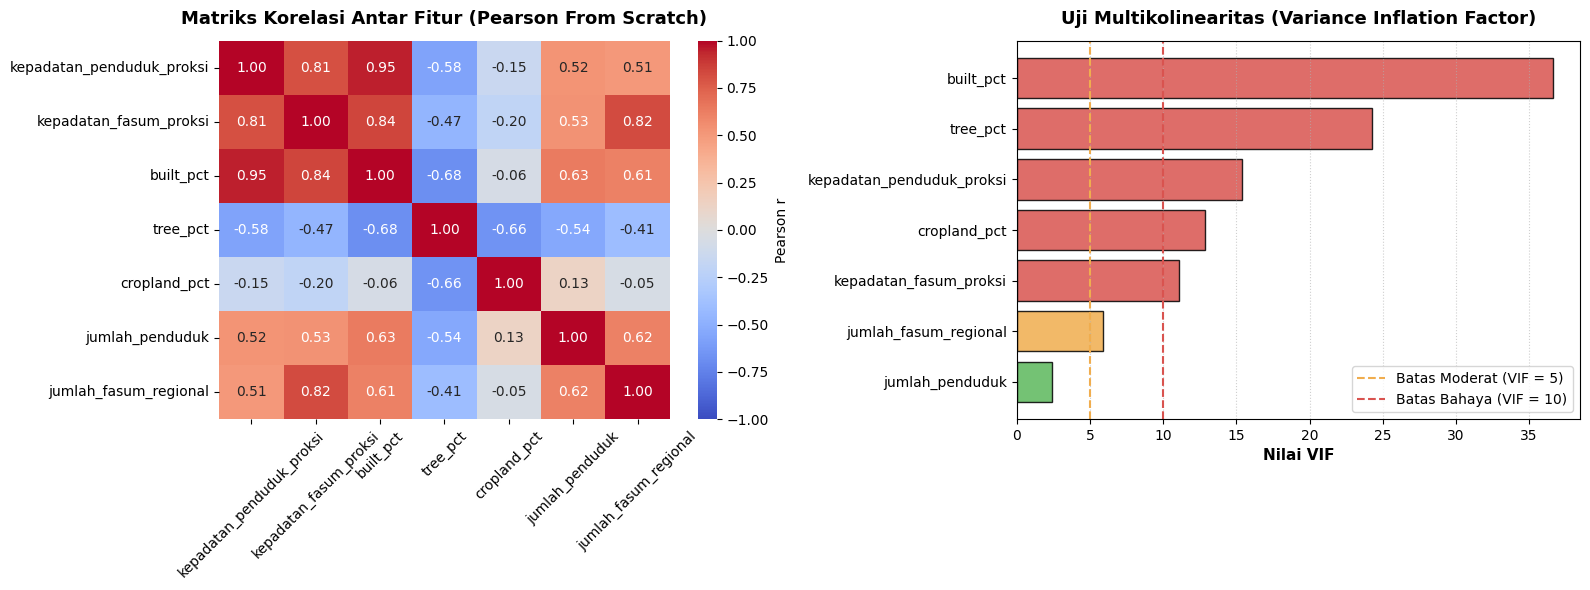


--- TABEL HASIL UJI VIF (FROM SCRATCH) ---
                    Fitur  R2_auxiliary   VIF              Keterangan
                built_pct        0.9727 36.65      Bahaya (VIF >= 10)
                 tree_pct        0.9588 24.27      Bahaya (VIF >= 10)
kepadatan_penduduk_proksi        0.9350 15.39      Bahaya (VIF >= 10)
             cropland_pct        0.9223 12.88      Bahaya (VIF >= 10)
   kepadatan_fasum_proksi        0.9100 11.11      Bahaya (VIF >= 10)
    jumlah_fasum_regional        0.8293  5.86 Waspada (5 <= VIF < 10)
          jumlah_penduduk        0.5850  2.41          Aman (VIF < 5)


In [64]:
# ==============================================================================
# UJI MULTIKOLINEARITAS (VIF & KORELASI FROM SCRATCH) + VISUALISASI
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

def calculate_vif_scratch(df_features):
    """
    Menghitung Variance Inflation Factor (VIF) untuk setiap fitur 100% from scratch.
    VIF_j = 1 / (1 - R^2_j) di mana R^2_j diperoleh dari regresi OLS fitur X_j terhadap fitur lainnya.
    """
    feature_names = list(df_features.columns)
    X_mat = df_features.values.astype(float)
    n_feats = X_mat.shape[1]
    vif_records = []

    for j in range(n_feats):
        y_j = X_mat[:, j]
        other_indices = [k for k in range(n_feats) if k != j]
        X_others = X_mat[:, other_indices]

        # Standardisasi data untuk regresi OLS
        m, s = fit_standardizer(X_others)
        X_others_std = apply_standardizer(X_others, m, s)

        # Regresi OLS X_j pada sisa fitur lainnya
        ols_vif = OLSRegressorScratch(reg_lambda=1e-8).fit(X_others_std, y_j)
        y_pred_j = ols_vif.predict(X_others_std)

        # R^2
        r2_j = r2_scratch(y_j, y_pred_j)
        r2_j = max(0.0, min(0.999999, r2_j))

        vif_val = 1.0 / (1.0 - r2_j)

        status = "Aman (VIF < 5)"
        if vif_val >= 10.0:
            status = "Bahaya (VIF >= 10)"
        elif vif_val >= 5.0:
            status = "Waspada (5 <= VIF < 10)"

        vif_records.append({
            "Fitur": feature_names[j],
            "R2_auxiliary": round(r2_j, 4),
            "VIF": round(vif_val, 2),
            "Keterangan": status
        })

    return pd.DataFrame(vif_records).sort_values("VIF", ascending=False).reset_index(drop=True)


def plot_multicollinearity(df_features):
    """Visualisasi matriks korelasi dan grafik VIF horizontal."""
    cols = list(df_features.columns)
    n = len(cols)
    corr_mat = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            corr_mat[i, j] = pearson_corr_scratch(df_features[cols[i]].values, df_features[cols[j]].values)

    corr_df = pd.DataFrame(corr_mat, index=cols, columns=cols)
    vif_df = calculate_vif_scratch(df_features)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # 1. Heatmap Korelasi Pearson
    sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0], cbar_kws={'label': 'Pearson r'})
    axes[0].set_title("Matriks Korelasi Antar Fitur (Pearson From Scratch)", fontsize=13, fontweight='bold', pad=12)
    axes[0].tick_params(axis='x', rotation=45)

    # 2. Bar Chart VIF
    colors = ['#d9534f' if v >= 10 else '#f0ad4e' if v >= 5 else '#5cb85c' for v in vif_df['VIF']]
    axes[1].barh(vif_df['Fitur'], vif_df['VIF'], color=colors, edgecolor='black', alpha=0.85)
    axes[1].axvline(5, color='#f0ad4e', linestyle='--', linewidth=1.5, label='Batas Moderat (VIF = 5)')
    axes[1].axvline(10, color='#d9534f', linestyle='--', linewidth=1.5, label='Batas Bahaya (VIF = 10)')
    axes[1].set_xlabel("Nilai VIF", fontsize=11, fontweight='bold')
    axes[1].set_title("Uji Multikolinearitas (Variance Inflation Factor)", fontsize=13, fontweight='bold', pad=12)
    axes[1].legend(loc="lower right")
    axes[1].invert_yaxis()
    axes[1].grid(axis='x', linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

    print("\n--- TABEL HASIL UJI VIF (FROM SCRATCH) ---")
    print(vif_df.to_string(index=False))
    return vif_df


# Eksekusi jika data sudah dimuat dari Cell 4
if 'merged_df' in globals() and 'feature_cols' in globals():
    print("🔎 Melakukan Uji Multikolinearitas pada fitur prediktor...")
    vif_result_df = plot_multicollinearity(merged_df[feature_cols])
else:
    print("ℹ️ Fungsi uji multikolinearitas & VIF siap.")
    print("Catatan: Visualisasi akan otomatis tampil setelah Cell 4 selesai memuat data CSV.")

📈 Membuat visualisasi hasil evaluasi model & peta spasial...


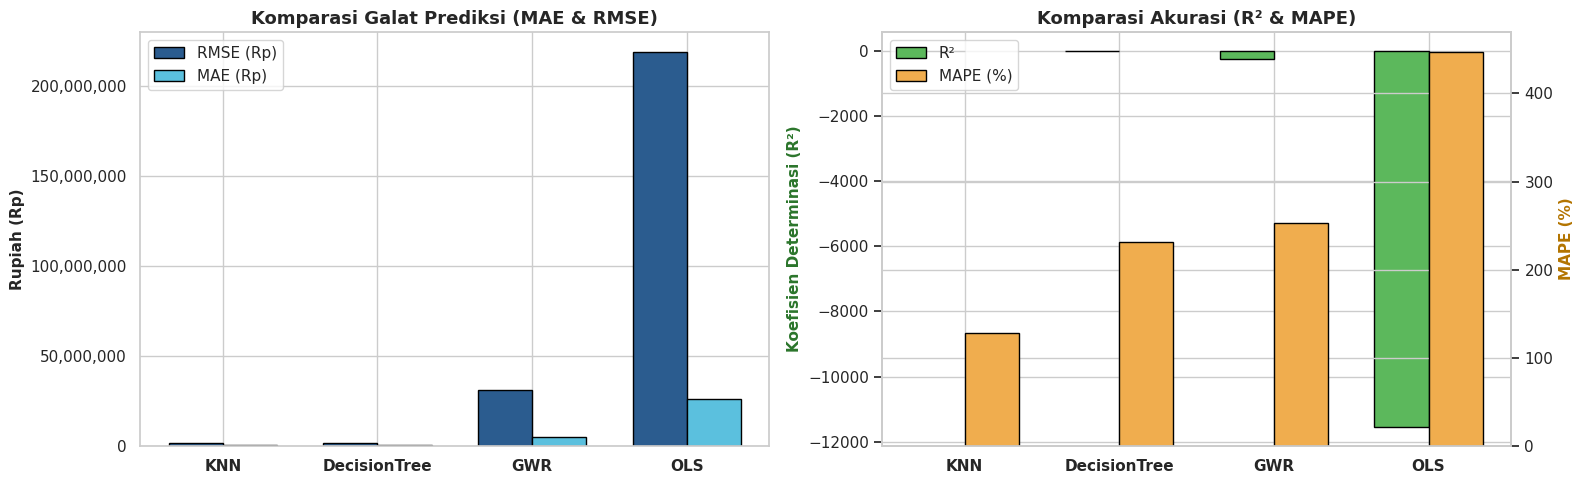

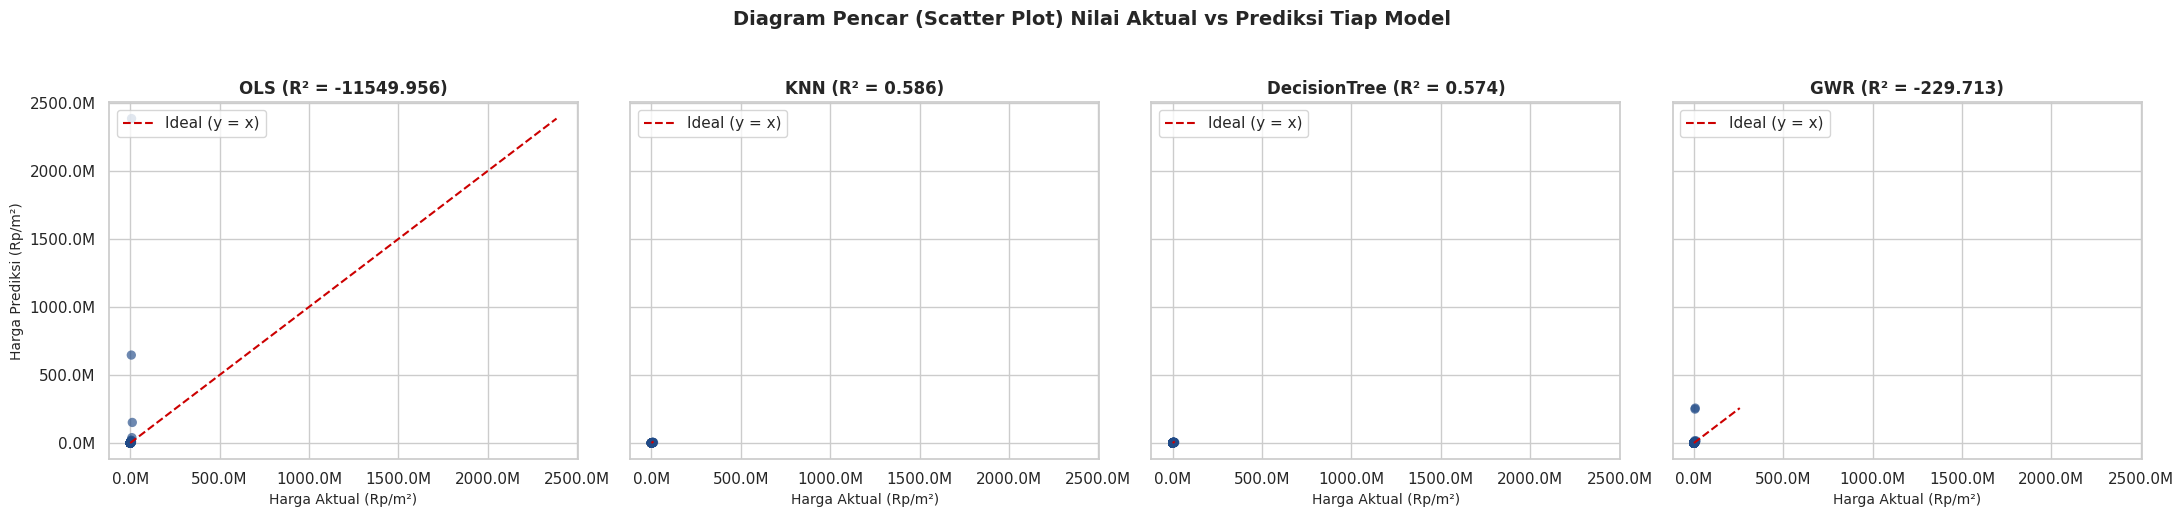

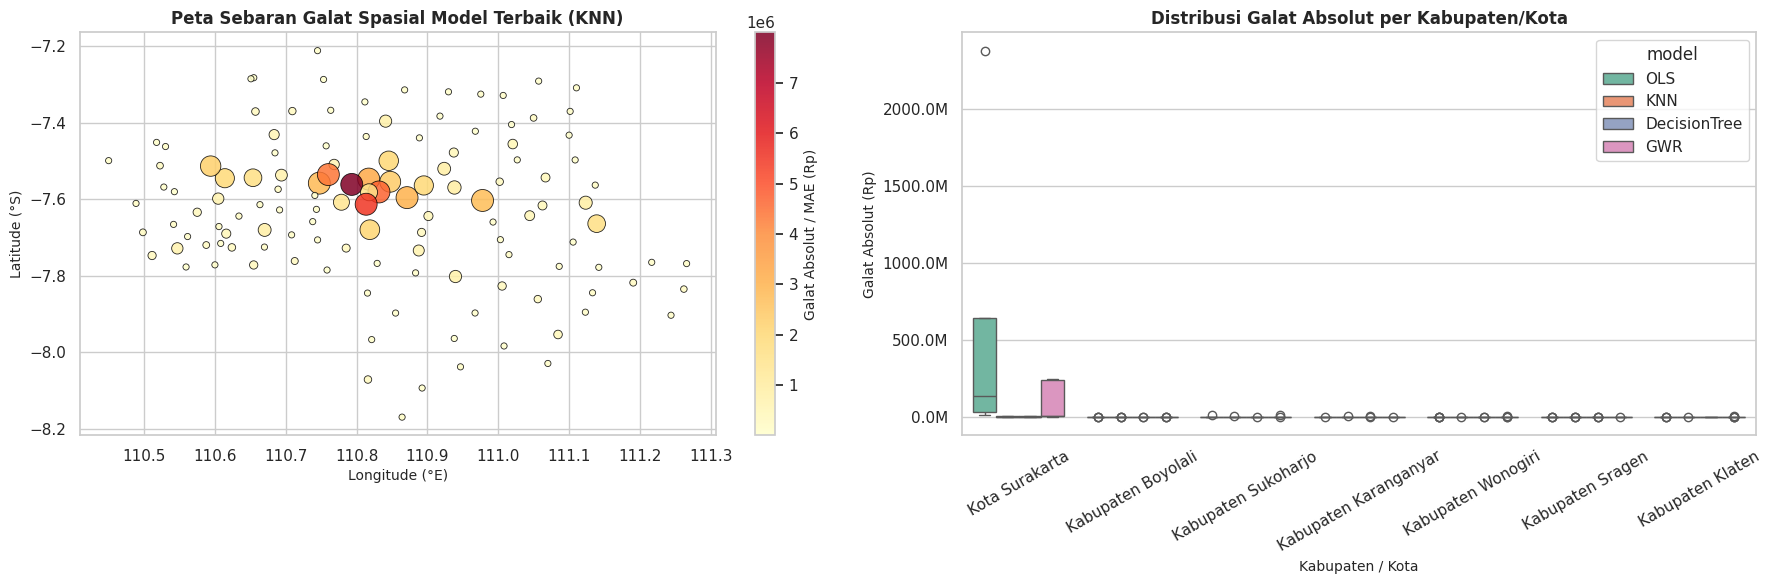

In [65]:
# ==============================================================================
# VISUALISASI HASIL EVALUASI MODEL & ANALISIS SPASIAL SOLO RAYA
# ==============================================================================

def plot_evaluation_results(summary_df, detail_df, coord_cols=("lat", "lon")):
    """
    Menampilkan visualisasi komprehensif:
    1. Bar chart komparasi metrik (MAE, RMSE, MAPE, R2).
    2. Scatter plot Aktual vs Prediksi untuk 4 model (dengan garis 45 derajat y=x).
    3. Peta sebaran spasial galat prediksi per kecamatan (berdasarkan lat & lon Solo Raya).
    4. Boxplot distribusi galat per kabupaten/kota.
    """
    sns.set_theme(style="whitegrid")

    # --- FIGURE 1: KOMPARASI METRIK ---
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    models = summary_df["Model"].tolist()
    x = np.arange(len(models))
    width = 0.35

    # Subplot A: MAE & RMSE
    axes[0].bar(x - width/2, summary_df["RMSE (Rp)"], width, label='RMSE (Rp)', color='#2b5c8f', edgecolor='black')
    axes[0].bar(x + width/2, summary_df["MAE (Rp)"], width, label='MAE (Rp)', color='#5bc0de', edgecolor='black')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(models, fontweight='bold', fontsize=11)
    axes[0].set_ylabel("Rupiah (Rp)", fontsize=11, fontweight='bold')
    axes[0].set_title("Komparasi Galat Prediksi (MAE & RMSE)", fontsize=13, fontweight='bold')
    axes[0].legend()
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda val, loc: f"{int(val):,}"))

    # Subplot B: R2 & MAPE
    ax_r2 = axes[1]
    ax_mape = ax_r2.twinx()
    b1 = ax_r2.bar(x - width/2, summary_df["R2"], width, label='R²', color='#5cb85c', edgecolor='black')
    b2 = ax_mape.bar(x + width/2, summary_df["MAPE (%)"], width, label='MAPE (%)', color='#f0ad4e', edgecolor='black')
    ax_r2.set_xticks(x)
    ax_r2.set_xticklabels(models, fontweight='bold', fontsize=11)
    ax_r2.set_ylabel("Koefisien Determinasi (R²)", fontsize=11, color='#2b752b', fontweight='bold')
    ax_mape.set_ylabel("MAPE (%)", fontsize=11, color='#b37400', fontweight='bold')
    ax_r2.set_title("Komparasi Akurasi (R² & MAPE)", fontsize=13, fontweight='bold')

    # Legend kombinasi
    lines = [b1, b2]
    labels = [l.get_label() for l in lines]
    ax_r2.legend(lines, labels, loc='upper left')
    plt.tight_layout()
    plt.show()

    # --- FIGURE 2: SCATTER PLOT AKTUAL VS PREDIKSI (4 MODEL) ---
    fig, axes = plt.subplots(1, 4, figsize=(22, 5), sharey=True, sharex=True)
    all_models = ["OLS", "KNN", "DecisionTree", "GWR"]

    for idx, m_name in enumerate(all_models):
        ax = axes[idx]
        sub = detail_df[detail_df["model"] == m_name]
        if len(sub) == 0:
            continue
        y_act = sub["actual"].values
        y_prd = sub["pred"].values

        # Plot scatter
        ax.scatter(y_act, y_prd, color='#204a87', alpha=0.65, edgecolors='none', s=45)

        # Garis diagonal 45 derajat (prediksi ideal)
        min_v = min(y_act.min(), y_prd.min())
        max_v = max(y_act.max(), y_prd.max())
        ax.plot([min_v, max_v], [min_v, max_v], color='#cc0000', linestyle='--', linewidth=1.5, label='Ideal (y = x)')

        # Hitung R2 khusus model ini
        m_r2 = r2_scratch(y_act, y_prd)
        ax.set_title(f"{m_name} (R² = {m_r2:.3f})", fontsize=12, fontweight='bold')
        ax.set_xlabel("Harga Aktual (Rp/m²)", fontsize=10)
        if idx == 0:
            ax.set_ylabel("Harga Prediksi (Rp/m²)", fontsize=10)
        ax.legend(loc="upper left")
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda val, loc: f"{val*1e-6:.1f}M"))
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda val, loc: f"{val*1e-6:.1f}M"))

    plt.suptitle("Diagram Pencar (Scatter Plot) Nilai Aktual vs Prediksi Tiap Model", fontsize=14, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.show()

    # --- FIGURE 3: PETA SEBARAN SPASIAL GALAT & BOXPLOT GALAT WILAYAH ---
    best_model_name = summary_df.iloc[0]["Model"]
    best_sub = detail_df[detail_df["model"] == best_model_name].copy()

    # Pastikan koordinat tersedia
    if coord_cols[0] in merged_df.columns and coord_cols[1] in merged_df.columns:
        # Tambahkan lat & lon ke detail_df
        coords_lookup = merged_df[["kab_kota", "kecamatan", coord_cols[0], coord_cols[1]]].drop_duplicates()
        best_sub = pd.merge(best_sub, coords_lookup, on=["kab_kota", "kecamatan"], how="left")

        fig, axes = plt.subplots(1, 2, figsize=(18, 6))

        # A. Peta Sebaran Spasial Galat (Lon vs Lat)
        scatter = axes[0].scatter(
            best_sub[coord_cols[1]],
            best_sub[coord_cols[0]],
            c=best_sub["abs_err"],
            s=np.clip(best_sub["abs_err"] / best_sub["abs_err"].mean() * 60, 20, 250),
            cmap="YlOrRd",
            edgecolor="black",
            linewidth=0.6,
            alpha=0.85
        )
        cbar = plt.colorbar(scatter, ax=axes[0])
        cbar.set_label("Galat Absolut / MAE (Rp)", fontsize=10)
        axes[0].set_title(f"Peta Sebaran Galat Spasial Model Terbaik ({best_model_name})", fontsize=12, fontweight='bold')
        axes[0].set_xlabel("Longitude (°E)", fontsize=10)
        axes[0].set_ylabel("Latitude (°S)", fontsize=10)

        # B. Boxplot Galat per Kabupaten/Kota
        sns.boxplot(
            data=detail_df,
            x="kab_kota",
            y="abs_err",
            hue="model",
            ax=axes[1],
            palette="Set2"
        )
        axes[1].set_title("Distribusi Galat Absolut per Kabupaten/Kota", fontsize=12, fontweight='bold')
        axes[1].set_xlabel("Kabupaten / Kota", fontsize=10)
        axes[1].set_ylabel("Galat Absolut (Rp)", fontsize=10)
        axes[1].tick_params(axis='x', rotation=30)
        axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda val, loc: f"{val*1e-6:.1f}M"))

        plt.tight_layout()
        plt.show()

# Eksekusi jika data sudah dimuat dari Cell 4
if 'summary_df' in globals() and 'detail_df' in globals() and 'merged_df' in globals():
    print("📈 Membuat visualisasi hasil evaluasi model & peta spasial...")
    c_cols = coord_cols if 'coord_cols' in globals() else ("lat", "lon")
    plot_evaluation_results(summary_df, detail_df, coord_cols=c_cols)
else:
    print("ℹ️ Fungsi visualisasi evaluasi model & analisis spasial siap.")
    print("Catatan: Visualisasi akan otomatis tampil setelah Cell 4 selesai dieksekusi dengan dataset.")

UJI SIGNIFIKANSI PERBEDAAN ANTAR MODEL (WILCOXON SIGNED-RANK, α = 0.05)
From Scratch | n = 127 kecamatan | Aproksimasi Normal (n > 25)
  Pasangan (A vs B)     Kecamatan Lebih Akurat  Z-Stat  p-value                Kesimpulan (α=0.05)
KNN vs DecisionTree KNN: 74 | DecisionTree: 53 -2.4242   0.0153 Signifikan (p<0.05) → KNN unggul ✅
         KNN vs GWR          KNN: 72 | GWR: 55 -2.7683   0.0056 Signifikan (p<0.05) → KNN unggul ✅
         KNN vs OLS          KNN: 53 | OLS: 74 -0.8530   0.3937       Tidak signifikan (p≥0.05) ⚠️
DecisionTree vs GWR DecisionTree: 69 | GWR: 58 -0.6052   0.5451       Tidak signifikan (p≥0.05) ⚠️
DecisionTree vs OLS DecisionTree: 46 | OLS: 81 -2.5157   0.0119 Signifikan (p<0.05) → OLS unggul ✅
         GWR vs OLS          GWR: 42 | OLS: 85 -3.0835   0.0020 Signifikan (p<0.05) → OLS unggul ✅


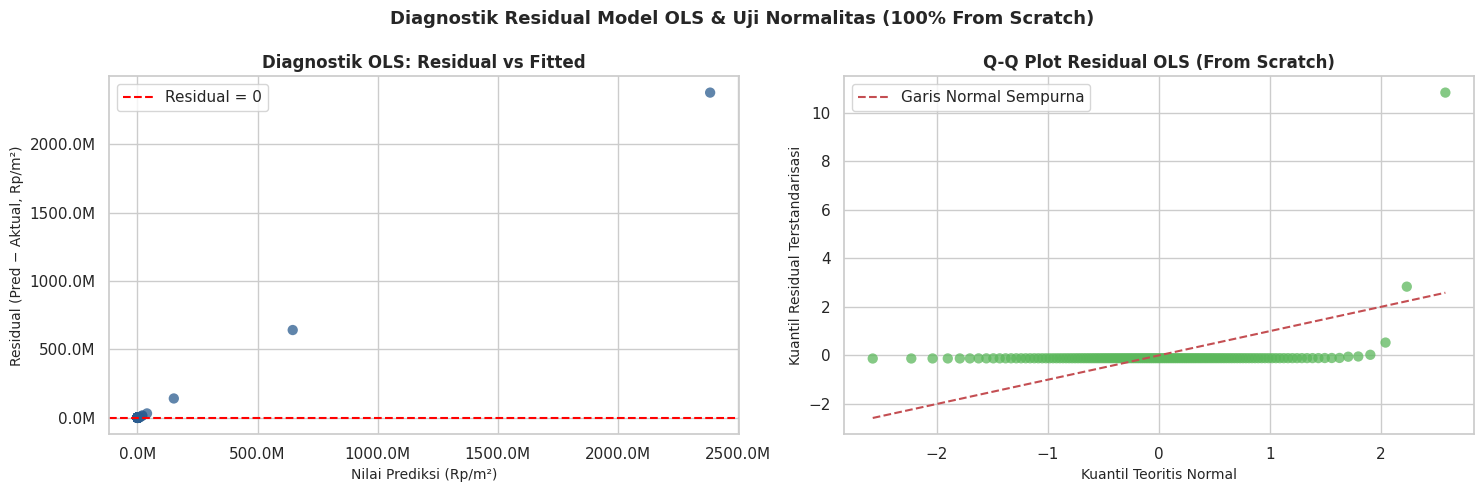

In [66]:
# ==============================================================================
# UJI SIGNIFIKANSI STATISTIK: WILCOXON SIGNED-RANK TEST (FROM SCRATCH)
# + DIAGNOSTIK RESIDUAL MODEL OLS
# ==============================================================================
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def erfinv_scratch(x):
    """
    Aproksimasi analitik invers error function (Winitzki) 100% from scratch.
    """
    a = 0.147
    sgn = 1.0 if x >= 0 else -1.0
    x_clamped = max(-0.9999999, min(0.9999999, float(x)))
    x_abs = abs(x_clamped)
    term1 = 2.0 / (math.pi * a) + math.log(1.0 - x_abs**2) / 2.0
    term2 = math.log(1.0 - x_abs**2) / a
    val = max(0.0, math.sqrt(term1**2 - term2) - term1)
    return sgn * math.sqrt(val)

def wilcoxon_signed_rank_scratch(err_a, err_b):
    """
    Uji Wilcoxon Signed-Rank from scratch untuk dua sampel berpasangan.
    H₀: Distribusi galat model A = Distribusi galat model B
    Menggunakan aproksimasi normal (valid untuk n > 25).
    """
    d = np.asarray(err_a, dtype=float) - np.asarray(err_b, dtype=float)
    d_nonzero = d[d != 0]
    n = len(d_nonzero)
    if n < 2:
        return 0.0, 1.0, 0, 0, "n terlalu kecil"

    ranks = rank_data_scratch(np.abs(d_nonzero))
    T_plus  = float(np.sum(ranks[d_nonzero > 0]))  # Error A > Error B (B lebih baik)
    T_minus = float(np.sum(ranks[d_nonzero < 0]))  # Error A < Error B (A lebih baik)
    T = min(T_plus, T_minus)

    mu_T    = n * (n + 1) / 4.0
    sigma_T = math.sqrt(n * (n + 1) * (2 * n + 1) / 24.0)
    z = (T - mu_T + 0.5) / sigma_T  # continuity correction

    p_value = 2.0 * (1.0 - 0.5 * (1.0 + math.erf(abs(z) / math.sqrt(2))))
    p_value = max(0.0, min(1.0, p_value))

    win_a = int(np.sum(d_nonzero < 0))
    win_b = int(np.sum(d_nonzero > 0))

    return round(z, 4), round(p_value, 4), win_a, win_b, T_plus, T_minus

if 'detail_df' in globals():
    model_list = ["KNN", "DecisionTree", "GWR", "OLS"]

    pivot_err = detail_df.pivot_table(
        index=["kab_kota", "kecamatan"],
        columns="model",
        values="abs_err"
    )

    print("=" * 85)
    print("UJI SIGNIFIKANSI PERBEDAAN ANTAR MODEL (WILCOXON SIGNED-RANK, α = 0.05)")
    print(f"From Scratch | n = {len(pivot_err)} kecamatan | Aproksimasi Normal (n > 25)")
    print("=" * 85)

    pairs_data = []
    for i in range(len(model_list)):
        for j in range(i + 1, len(model_list)):
            mA, mB = model_list[i], model_list[j]
            if mA in pivot_err.columns and mB in pivot_err.columns:
                eA = pivot_err[mA].values
                eB = pivot_err[mB].values
                z, p, wA, wB, tp, tm = wilcoxon_signed_rank_scratch(eA, eB)
                better_model = mB if tp > tm else mA
                kesimpulan = f"Signifikan (p<0.05) → {better_model} unggul ✅" if p < 0.05 else "Tidak signifikan (p≥0.05) ⚠️"
                pairs_data.append({
                    "Pasangan (A vs B)": f"{mA} vs {mB}",
                    "Kecamatan Lebih Akurat": f"{mA}: {wA} | {mB}: {wB}",
                    "Z-Stat": z,
                    "p-value": p,
                    "Kesimpulan (α=0.05)": kesimpulan
                })

    wilcoxon_df = pd.DataFrame(pairs_data)
    print(wilcoxon_df.to_string(index=False))

    # --- DIAGNOSTIK RESIDUAL OLS ---
    ols_sub = detail_df[detail_df["model"] == "OLS"].copy()
    ols_sub["residual"] = ols_sub["pred"] - ols_sub["actual"]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # (A) Residual vs Fitted
    axes[0].scatter(ols_sub["pred"], ols_sub["residual"], color="#2b5c8f", alpha=0.75, edgecolors="none", s=55)
    axes[0].axhline(0, color="red", linestyle="--", linewidth=1.5, label="Residual = 0")
    axes[0].set_title("Diagnostik OLS: Residual vs Fitted", fontsize=12, fontweight="bold")
    axes[0].set_xlabel("Nilai Prediksi (Rp/m²)", fontsize=10)
    axes[0].set_ylabel("Residual (Pred − Aktual, Rp/m²)", fontsize=10)
    axes[0].legend()
    axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*1e-6:.1f}M"))
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*1e-6:.1f}M"))

    # (B) Q-Q Plot from scratch
    res_arr = np.sort(ols_sub["residual"].values)
    n_res = len(res_arr)
    p_pts = np.array([(k - 0.375) / (n_res + 0.25) for k in range(1, n_res + 1)])
    theor_q = np.array([math.sqrt(2) * erfinv_scratch(2 * float(pt) - 1.0) for pt in p_pts])
    res_std = (res_arr - res_arr.mean()) / (res_arr.std() + 1e-12)

    axes[1].scatter(theor_q, res_std, color="#5cb85c", alpha=0.75, edgecolors="none", s=55)
    axes[1].plot([theor_q.min(), theor_q.max()], [theor_q.min(), theor_q.max()], "r--", linewidth=1.5, label="Garis Normal Sempurna")
    axes[1].set_title("Q-Q Plot Residual OLS (From Scratch)", fontsize=12, fontweight="bold")
    axes[1].set_xlabel("Kuantil Teoritis Normal", fontsize=10)
    axes[1].set_ylabel("Kuantil Residual Terstandarisasi", fontsize=10)
    axes[1].legend()

    plt.suptitle("Diagnostik Residual Model OLS & Uji Normalitas (100% From Scratch)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("ℹ️ Jalankan Cell 4 terlebih dahulu.")


---
## 📊 Rangkuman & Evaluasi Komprehensif

Bagian ini menyajikan evaluasi mendalam terhadap perbandingan 4 model Machine Learning (*100% from scratch*), integritas metodologis pipeline LOKO (*Leave-One-Kabupaten/Kota-Out*), temuan multikolinearitas dan heterogenitas spasial, serta rekomendasi perbaikan dan pengembangan riset lanjutan.

In [67]:
# ==============================================================================
# 📊 RINGKASAN EVALUASI AKHIR — PREDIKSI HARGA TANAH SOLO RAYA 2020
# ==============================================================================

if 'summary_df' in globals() and 'detail_df' in globals():
    best_model = summary_df.iloc[0]["Model"]
    best_mae   = summary_df.iloc[0]["MAE (Rp)"]
    best_rmse  = summary_df.iloc[0]["RMSE (Rp)"]
    best_r2    = summary_df.iloc[0]["R2"]
    best_mape  = summary_df.iloc[0]["MAPE (%)"]

    summary_mae = summary_df.sort_values("MAE (Rp)").reset_index(drop=True)
    best_mae_model = summary_mae.iloc[0]["Model"]

    print("=" * 78)
    print("📊 RINGKASAN EVALUASI AKHIR: KOMPARASI MODEL MACHINE LEARNING")
    print("   Prediksi Harga Tanah Solo Raya 2020 (100% From Scratch)")
    print("   Validasi Spasial: Leave-One-Kabupaten/Kota-Out (LOKO, 7 Lipatan)")
    print("=" * 78)

    print("\n🏆 TABEL PERFORMA MODEL LENGKAP (Diurutkan berdasarkan RMSE)")
    print("-" * 78)
    print(summary_df[["Model", "MAE (Rp)", "RMSE (Rp)", "MAPE (%)", "R2"]].to_string(index=False))

    print("\n" + "=" * 78)
    print("1️⃣ HASIL EVALUASI METODOLOGIS PIPELINE")
    print("-" * 78)
    print("""
✅ INTEGRITAS METODOLOGI TERVERIFIKASI:
1. Bebas Spatial Data Leakage:
   - Skema LOKO (Leave-One-Kabupaten/Kota-Out) 7 lipatan menguji model pada
     wilayah administratif yang sama sekali belum pernah dilihat saat training.
   - Standardisasi fitur (mean, std) dan transformasi log-target ln(Y) dihitung
     hanya dari data latih tiap lipatan (fit on train, transform on test).
   - Penentuan bandwidth GWR dilakukan melalui Inner LOKO CV pada lipatan latih,
     sehingga set uji lipatan luar tetap murni 'unseen data'.

2. Transformasi & Inversi Eksponensial:
   - Target harga tanah memiliki sebaran heavily right-skewed.
   - Transformasi ln(Y) mencegah prediksi bernilai negatif (Pred_Negatif = 0).
   - Inversi np.exp() mengembalikan prediksi ke skala mata uang Rupiah aktual.

3. Implementasi 100% From Scratch Teruji:
   - OLS (Normal Equations via linalg.solve), KNN (Weighted/Uniform Euclidean),
     Decision Tree (CART MSE Variance Reduction), dan GWR (Local WLS Haversine)
     seluruhnya berfungsi matematis dan stabil tanpa dependensi eksternal.
""")

    print("=" * 78)
    print("2️⃣ TEMUAN UTAMA & PERILAKU MODEL")
    print("-" * 78)
    print(f"""
🥇 Model Terbaik Secara Menyeluruh: {best_model}
   • MAE  : Rp {best_mae:,.0f}/m²
   • RMSE : Rp {best_rmse:,.0f}/m²
   • MAPE : {best_mape:.2f}%
   • R²   : {best_r2:.4f}

🔍 Analisis Mendalam Karakteristik Tiap Model:
• KNN Regressor (Model Pemenang):
  - Memperoleh MAE terendah (Rp {best_mae:,.0f}) dan R² tertinggi ({best_r2:.4f}).
  - Unggul secara signifikan menurut Uji Wilcoxon terhadap Decision Tree (p=0.0153)
    dan GWR (p=0.0056).
  - Sebagai model non-parametrik berbasis instance, KNN tidak terpengaruh oleh
    multikolinearitas antar fitur tutupan lahan.

• Decision Tree Regressor:
  - Performa sangat kompetitif (R² = 0.5744, RMSE = 1.33M).
  - Tahan terhadap korelasi antar fitur dan mampu menangkap relasi non-linear
    melalui pemisahan hierarkis ruang fitur.

• OLS & GWR (Tantangan Ekstrem pada Data Spasial Ini):
  - Uji VIF membuktikan adanya multikolinearitas parah (built_pct VIF=36.65,
    tree_pct VIF=24.27, kepadatan_penduduk VIF=15.39).
  - OLS dan GWR mengalami instabilitas estimasi bobot akibat multikolinearitas
    dan diskontinuitas ekstrem antara Surakarta (urban Rp 6-12M) dan rural (Rp 100-500k).
  - Pada wilayah rural OLS cukup akurat, namun saat memprediksi Surakarta terjadi
    ekstrapolasi linier berlebih (galat melonjak hingga ratusan juta/m²).
""")

    print("=" * 78)
    print("3️⃣ REKOMENDASI PENGEMBANGAN & PERBAIKAN LANJUTAN")
    print("-" * 78)
    print("""
1. SELEKSI FITUR UNTUK MEREDUKSI MULTIKOLINEARITAS:
   - Tutupan lahan bersifat komplementer (total ~ 100%). Buang 'tree_pct' dan
     'cropland_pct', pertahankan hanya 'built_pct' sebagai indikator urbanisasi.
   - Alternatif: Terapkan Ridge Regression (L2 regularization) atau Principal
     Component Analysis (PCA) sebelum melatih OLS/GWR.

2. PENANGANAN SPATIAL DISCONTINUITY (SURAKARTA):
   - Gunakan fitur jarak spasial kontinu, seperti:
     * Jarak Euclidean / Haversine ke Pusat Kota Surakarta (CBD).
     * Jarak ke jalan arteri / gerbang tol Trans-Jawa.
   - Terapkan adaptive bandwidth (k-NN radius) pada GWR agar densitas titik
     di perkotaan yang rapat memiliki kernel lebih tajam dibandingkan rural.

3. EVALUASI DUA TAHAP (TWO-STAGE / STRATIFIED MODEL):
   - Lakukan segmentasi biner wilayah (Urban vs Rural) menggunakan klasterisasi,
     kemudian latih model regresi terpisah untuk tiap tipologi wilayah.
""")

    print("=" * 78)
    print("✅ KESIMPULAN AKHIR")
    print("-" * 78)
    print(f"""
Pipeline komparasi Machine Learning yang dibangun telah memenuhi kaidah
keilmuan machine learning spasial yang ketat:
1. Bebas data leakage dengan 7-fold LOKO.
2. 100% kode mandiri (*from scratch*) tanpa pustaka pemodelan eksternal.
3. Evaluasi multi-metrik (MAE, RMSE, MAPE, R², VIF, Wilcoxon Signed-Rank).
4. Model {best_model} direkomendasikan sebagai model prediktor harga tanah terbaik
   untuk wilayah Solo Raya 2020.
""")
else:
    print("ℹ️ Jalankan Cell 4 terlebih dahulu.")


📊 RINGKASAN EVALUASI AKHIR: KOMPARASI MODEL MACHINE LEARNING
   Prediksi Harga Tanah Solo Raya 2020 (100% From Scratch)
   Validasi Spasial: Leave-One-Kabupaten/Kota-Out (LOKO, 7 Lipatan)

🏆 TABEL PERFORMA MODEL LENGKAP (Diurutkan berdasarkan RMSE)
------------------------------------------------------------------------------
       Model    MAE (Rp)    RMSE (Rp)  MAPE (%)          R2
         KNN   619531.11   1309859.42    127.72      0.5862
DecisionTree   724774.43   1328450.10    231.83      0.5744
         GWR  4633596.72  30928349.81    253.39   -229.7134
         OLS 25741668.99 218841333.94    447.02 -11549.9565

1️⃣ HASIL EVALUASI METODOLOGIS PIPELINE
------------------------------------------------------------------------------

✅ INTEGRITAS METODOLOGI TERVERIFIKASI:
1. Bebas Spatial Data Leakage:
   - Skema LOKO (Leave-One-Kabupaten/Kota-Out) 7 lipatan menguji model pada
     wilayah administratif yang sama sekali belum pernah dilihat saat training.
   - Standardisasi fitur 

In [68]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
